In [1]:
import numpy as np 
import pandas as pd
import torch 
import os
from torch.utils.data import Dataset,DataLoader
import sys
from pathlib import Path
import matplotlib.pyplot as plt


In [2]:
DATA_ROOT = Path(
    "/home/rittick-dutta/Desktop/Research/"
    "symile-mimic/symile-mimic-aws/data_npy"
)

print("DATA_ROOT exists:", DATA_ROOT.is_dir())

DATA_ROOT exists: True


In [3]:
DATASET_PATH = DATA_ROOT.parent
train_df = pd.read_csv(DATASET_PATH / "train.csv")

print("Rows and columns in train_df:", train_df.shape)
display(train_df.head())


Rows and columns in train_df: (10000, 118)


,subject_id,hadm_id,cxr_path,Atelectasis,Cardiomegaly,Edema,Lung Opacity,No Finding,Pleural Effusion,ecg_path,...,50910_percentile,52135_percentile,Consolidation,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Pleural Other,Pneumonia,Pneumothorax,Support Devices
0,17628012,25296721,files/p17/p17628012/s51943003/a8e58d81-689f98c...,1.0,NaN,1.0,1.0,NaN,1.0,files/p1762/p17628012/s46857043/46857043,...,NaN,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,0.0,1.0
1,11686629,26188372,files/p11/p11686629/s50480565/a2fb7bee-758a13b...,1.0,NaN,-1.0,1.0,NaN,NaN,files/p1168/p11686629/s45321834/45321834,...,NaN,NaN,NaN,-1.0,NaN,NaN,NaN,1.0,0.0,1.0
2,14798598,20652011,files/p14/p14798598/s55516445/5e518f88-5192986...,1.0,1.0,-1.0,NaN,NaN,1.0,files/p1479/p14798598/s45042373/45042373,...,0.701479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,12672152,26177106,files/p12/p12672152/s52146889/ff1c767f-4899cef...,NaN,1.0,1.0,1.0,NaN,1.0,files/p1267/p12672152/s45735573/45735573,...,0.284334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0
4,18963838,22280697,files/p18/p18963838/s55615398/7fc1b58f-25c0ad8...,1.0,1.0,0.0,-1.0,NaN,1.0,files/p1896/p18963838/s47523342/47523342,...,NaN,0.19906,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(train_df.columns.tolist())

['subject_id', 'hadm_id', 'cxr_path', 'Atelectasis', 'Cardiomegaly', 'Edema', 'Lung Opacity', 'No Finding', 'Pleural Effusion', 'ecg_path', '51221', '51265', '50912', '50971', '51222', '51301', '51249', '51279', '51250', '51248', '51277', '51006', '50983', '50902', '50882', '50868', '50931', '50960', '50893', '50970', '51237', '51274', '51275', '51146', '51256', '51254', '51200', '51244', '52172', '50934', '51678', '50947', '50861', '50878', '50813', '50863', '50885', '50820', '50862', '50802', '50821', '50804', '50818', '52075', '52073', '52074', '52069', '51133', '50910', '52135', '51221_percentile', '51265_percentile', '50912_percentile', '50971_percentile', '51222_percentile', '51301_percentile', '51249_percentile', '51279_percentile', '51250_percentile', '51248_percentile', '51277_percentile', '51006_percentile', '50983_percentile', '50902_percentile', '50882_percentile', '50868_percentile', '50931_percentile', '50960_percentile', '50893_percentile', '50970_percentile', '51237_per

In [5]:
PIPELINE_ROOT = DATASET_PATH.parents[1] / "Pipeline2"
if str(PIPELINE_ROOT) not in sys.path:
    sys.path.insert(0, str(PIPELINE_ROOT))
from utils.data_helper import TARGETS

print("Number of prediction targets:", len(TARGETS))
display(train_df[["subject_id", "hadm_id", *TARGETS]].head(10))

Number of prediction targets: 14


,subject_id,hadm_id,Atelectasis,Cardiomegaly,Consolidation,Edema,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Lung Opacity,No Finding,Pleural Effusion,Pleural Other,Pneumonia,Pneumothorax,Support Devices
0,17628012,25296721,1.0,NaN,NaN,1.0,-1.0,NaN,NaN,1.0,NaN,1.0,NaN,NaN,0.0,1.0
1,11686629,26188372,1.0,NaN,NaN,-1.0,-1.0,NaN,NaN,1.0,NaN,NaN,NaN,1.0,0.0,1.0
2,14798598,20652011,1.0,1.0,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
3,12672152,26177106,NaN,1.0,NaN,1.0,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,0.0,1.0
4,18963838,22280697,1.0,1.0,NaN,0.0,NaN,NaN,NaN,-1.0,NaN,1.0,NaN,NaN,NaN,NaN
5,19931382,28486659,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0
6,14815961,23579413,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
7,13855132,28064016,1.0,1.0,NaN,1.0,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,NaN
8,15632977,29297479,NaN,1.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1.0
9,12562737,28903038,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,0.0,1.0


In [6]:
#we need to use data_npy to use the proccesses cxr image pixels.

In [7]:
cxr = np.load(DATA_ROOT /"train" / "cxr_train.npy",mmap_mode='r')

print("Shape of cxr:", cxr[0].shape)

Shape of cxr: (3, 320, 320)


In [8]:

arrays = {}

for name in [
    "cxr",
    "ecg",
    "labs_percentiles",
    "labs_missingness",
    "hadm_id",
]:
    path = DATA_ROOT / "train" / f"{name}_train.npy"
    arrays[name] = np.load(path, mmap_mode="r", allow_pickle=False)

    print(
        f"{name}: shape={arrays[name].shape}, "
        f"dtype={arrays[name].dtype}"
    )

cxr: shape=(10000, 3, 320, 320), dtype=float32
ecg: shape=(10000, 1, 5000, 12), dtype=float32
labs_percentiles: shape=(10000, 50), dtype=float32
labs_missingness: shape=(10000, 50), dtype=int64
hadm_id: shape=(10000,), dtype=int64


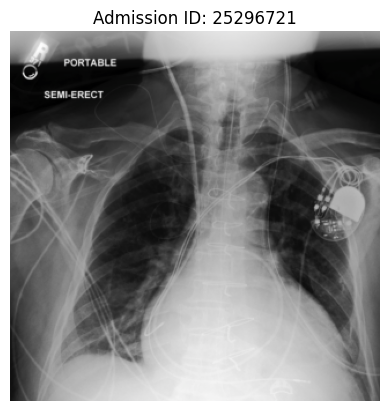

In [9]:
idx=0 

image = arrays["cxr"][idx].transpose(1, 2, 0)  # Convert from (C, H, W) to (H, W, C)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = np.clip(image * std + mean, 0, 1)  # Unnormalize and clip to [0, 1]

plt.imshow(image)
plt.title(f"Admission ID: {arrays['hadm_id'][idx]}")
plt.axis('off')
plt.show()


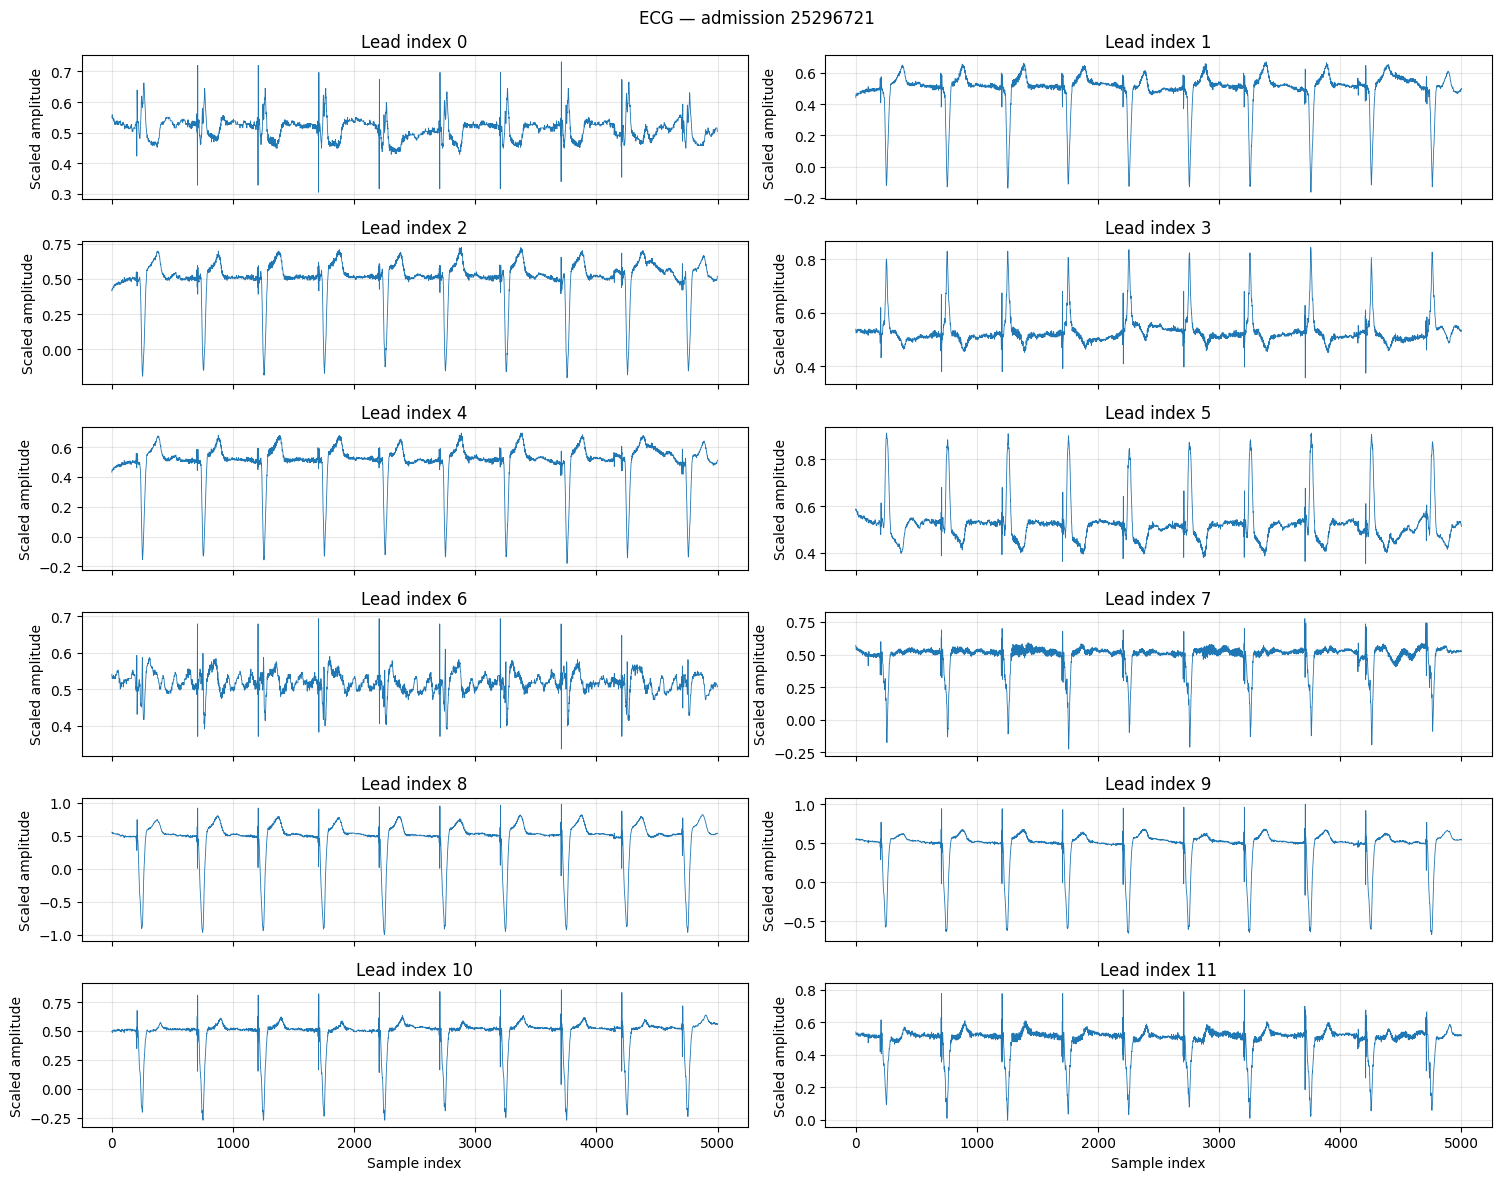

In [10]:

idx = 0
ecg = arrays["ecg"][idx, 0]  # Shape: (5000, 12)

fig, axes = plt.subplots(6, 2, figsize=(15, 12), sharex=True)

for lead, ax in enumerate(axes.flat):
    ax.plot(ecg[:, lead], linewidth=0.6)
    ax.set_title(f"Lead index {lead}")
    ax.set_ylabel("Scaled amplitude")
    ax.grid(alpha=0.3)

for ax in axes[-1]:
    ax.set_xlabel("Sample index")

fig.suptitle(f"ECG — admission {arrays['hadm_id'][idx]}")
plt.tight_layout()
plt.show()

In [11]:
test_arrays = {}

for name in ["hadm_id", "label_hadm_id", "label"]:
    path = DATA_ROOT / "test" / f"{name}_test.npy"
    test_arrays[name] = np.load(
        path, mmap_mode="r", allow_pickle=False
    )
    print(name, test_arrays[name].shape, test_arrays[name].dtype)

hadm_id (4640,) int64
label_hadm_id (4640,) int64
label (4640,) int64


In [12]:
import pandas as pd

test_df = pd.read_csv(DATA_ROOT.parent / "test.csv")

# Keep one original sample per admission.
test_df = test_df[test_df["label"] == 1]

display(test_df[["hadm_id", "cxr_path", "ecg_path", *TARGETS]])

print("Test admissions:", len(test_df))

,hadm_id,cxr_path,ecg_path,Atelectasis,Cardiomegaly,Consolidation,Edema,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Lung Opacity,No Finding,Pleural Effusion,Pleural Other,Pneumonia,Pneumothorax,Support Devices
0,28401574,files/p11/p11653463/s53728075/2ea18533-8ecdc76...,files/p1165/p11653463/s45743342/45743342,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
1,21846096,files/p13/p13606080/s55651307/7d1e94aa-110edb1...,files/p1360/p13606080/s44060073/44060073,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN
2,28898695,files/p18/p18454638/s53597307/33fd267a-091dccc...,files/p1845/p18454638/s43955252/43955252,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,1.0
3,27652514,files/p16/p16522692/s57313388/ea6f2577-4a85820...,files/p1652/p16522692/s41052901/41052901,-1.0,NaN,NaN,NaN,-1.0,NaN,NaN,1.0,NaN,-1.0,NaN,1.0,0.0,1.0
4,23484796,files/p11/p11197198/s52726920/d7811595-7c9a8e9...,files/p1119/p11197198/s44793535/44793535,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,28315320,files/p17/p17866064/s56909913/b2b3e534-225e3a0...,files/p1786/p17866064/s47365230/47365230,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0
460,22840791,files/p12/p12726753/s56051819/c90cf7eb-8499d05...,files/p1272/p12726753/s44899600/44899600,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
461,29778475,files/p15/p15145615/s50093490/88522319-964533d...,files/p1514/p15145615/s46204042/46204042,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0
462,24235468,files/p17/p17562503/s59040489/46c31244-2ee32b4...,files/p1756/p17562503/s43612494/43612494,NaN,1.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN


Test admissions: 464


In [13]:
import pandas as pd

test_table = pd.DataFrame({
    "candidate_hadm_id": test_arrays["hadm_id"].reshape(-1),
    "query_hadm_id": test_arrays["label_hadm_id"].reshape(-1),
    "retrieval_label": test_arrays["label"].reshape(-1),
})

display(test_table.head(15))

print("Total rows:", len(test_table))
print("Unique candidate admissions:",
      test_table["candidate_hadm_id"].nunique())
print("Unique queries:", test_table["query_hadm_id"].nunique())
print("Retrieval label counts:")
print(test_table["retrieval_label"].value_counts())

,candidate_hadm_id,query_hadm_id,retrieval_label
0,28401574,28401574,1
1,21846096,21846096,1
2,28898695,28898695,1
3,27652514,27652514,1
4,23484796,23484796,1
5,23530010,23530010,1
6,22388635,22388635,1
7,22260012,22260012,1
8,24384053,24384053,1
9,24486361,24486361,1


Total rows: 4640
Unique candidate admissions: 464
Unique queries: 464
Retrieval label counts:
retrieval_label
0    4176
1     464
Name: count, dtype: int64


In [14]:
#for test we will select the original test rows with retirval label 1  ,keeping each admission once .
#will use those same row incdices to select the corresponding cxr,ecg and labs data from the test arrays.
#then  will obtain the corresponding 14 CheXpert labels from the csv,verifying admission ids
#then compare the predictions with valid targets using label_mask


In [15]:
test_dir = DATA_ROOT / "test"
test_csv = pd.read_csv(DATA_ROOT.parent / "test.csv")

test_arrays = {
    name: np.load(
        test_dir / f"{name}_test.npy",
        mmap_mode="r",
        allow_pickle=False,
    )
    for name in [
        "cxr",
        "ecg",
        "labs_percentiles",
        "labs_missingness",
        "hadm_id",
        "label_hadm_id",
        "label",
    ]
}

hadm_ids = test_arrays["hadm_id"].reshape(-1)
query_ids = test_arrays["label_hadm_id"].reshape(-1)
retrieval_labels = test_arrays["label"].reshape(-1)

# Confirm every array and the CSV have matching sample counts.
assert all(len(a) == len(test_csv) for a in test_arrays.values())

# Confirm CSV rows correspond to the same array entries.
assert np.array_equal(test_csv["hadm_id"].to_numpy(), hadm_ids)
assert np.array_equal(test_csv["label_hadm_id"].to_numpy(), query_ids)
assert np.array_equal(test_csv["label"].to_numpy(), retrieval_labels)

print("CSV and arrays match.")

CSV and arrays match.


In [16]:
test_indices = np.flatnonzero(retrieval_labels == 1)

assert len(test_indices) > 0
assert np.array_equal(
    hadm_ids[test_indices],
    query_ids[test_indices],
)

clinical_test_df = (
    test_csv.iloc[test_indices]
    .copy()
    .reset_index(drop=True)
)

# Preserve the corresponding row number in the original NPY arrays.
clinical_test_df.insert(0, "array_index", test_indices)

assert clinical_test_df["hadm_id"].is_unique

print("Original retrieval rows:", len(test_csv))
print("Clinical test admissions:", len(clinical_test_df))

display(
    clinical_test_df[
        ["array_index", "subject_id", "hadm_id", *TARGETS]
    ].head(10)
)

Original retrieval rows: 4640
Clinical test admissions: 464


,array_index,subject_id,hadm_id,Atelectasis,Cardiomegaly,Consolidation,Edema,Enlarged Cardiomediastinum,Fracture,Lung Lesion,Lung Opacity,No Finding,Pleural Effusion,Pleural Other,Pneumonia,Pneumothorax,Support Devices
0,0,11653463,28401574,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
1,1,13606080,21846096,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN
2,2,18454638,28898695,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,1.0
3,3,16522692,27652514,-1.0,NaN,NaN,NaN,-1.0,NaN,NaN,1.0,NaN,-1.0,NaN,1.0,0.0,1.0
4,4,11197198,23484796,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
5,5,15907594,23530010,1.0,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,1.0
6,6,14865169,22388635,NaN,NaN,NaN,-1.0,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,NaN,NaN
7,7,18212068,22260012,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,NaN,NaN
8,8,14650506,24384053,NaN,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN,-1.0,NaN,NaN
9,9,14740322,24486361,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,1.0


In [17]:
raw_targets = clinical_test_df[TARGETS].to_numpy(dtype=np.float32)

allowed = np.isnan(raw_targets) | np.isin(raw_targets, [-1, 0, 1])
assert allowed.all(), "Unexpected target values."

# Only explicit 0 and 1 labels are valid for evaluation.
test_label_mask = np.isin(raw_targets, [0, 1])

# Unknown labels get placeholder zeros, but their masks remain False.
test_targets = np.where(
    test_label_mask, raw_targets, 0.0
).astype(np.float32)

print("Targets:", test_targets.shape)
print("Label masks:", test_label_mask.shape)

display(pd.DataFrame({
    "target": TARGETS,
    "positive": (raw_targets == 1).sum(axis=0),
    "negative": (raw_targets == 0).sum(axis=0),
    "uncertain": (raw_targets == -1).sum(axis=0),
    "unmentioned": np.isnan(raw_targets).sum(axis=0),
}))

Targets: (464, 14)
Label masks: (464, 14)


,target,positive,negative,uncertain,unmentioned
0,Atelectasis,141,5,22,296
1,Cardiomegaly,144,50,20,250
2,Consolidation,29,22,8,405
3,Edema,82,88,39,255
4,Enlarged Cardiomediastinum,28,15,30,391
5,Fracture,10,0,0,454
6,Lung Lesion,12,2,3,447
7,Lung Opacity,131,13,12,308
8,No Finding,69,0,0,395
9,Pleural Effusion,166,90,15,193


In [18]:
sample_index = 0
array_index = int(test_indices[sample_index])

sample = {
    "hadm_id": int(hadm_ids[array_index]),
    "cxr": test_arrays["cxr"][array_index],
    "ecg": test_arrays["ecg"][array_index],
    "labs": np.concatenate([
        test_arrays["labs_percentiles"][array_index],
        test_arrays["labs_missingness"][array_index],
    ]).astype(np.float32),
    "targets": test_targets[sample_index],
    "label_mask": test_label_mask[sample_index],
}

print("Admission:", sample["hadm_id"])
print("CXR:", sample["cxr"].shape)
print("ECG:", sample["ecg"].shape)
print("Labs:", sample["labs"].shape)

display(pd.DataFrame({
    "target": TARGETS,
    "original_label": raw_targets[sample_index],
    "stored_target": sample["targets"],
    "use_for_evaluation": sample["label_mask"],
}))

Admission: 28401574
CXR: (3, 320, 320)
ECG: (1, 5000, 12)
Labs: (100,)


,target,original_label,stored_target,use_for_evaluation
0,Atelectasis,1.0,1.0,True
1,Cardiomegaly,NaN,0.0,False
2,Consolidation,NaN,0.0,False
3,Edema,NaN,0.0,False
4,Enlarged Cardiomediastinum,NaN,0.0,False
5,Fracture,NaN,0.0,False
6,Lung Lesion,NaN,0.0,False
7,Lung Opacity,NaN,0.0,False
8,No Finding,NaN,0.0,False
9,Pleural Effusion,NaN,0.0,False
